# Plot color palette for dark and light mode

In [7]:
import matplotlib.pyplot as plt

PLOT_COLORS = {
    "light": [
        "#1762A0", "#A64600", "#006D69",
        "#7840A4", "#886000"
    ],
    "dark": [
        "#67B4F2", "#FFAB66", "#53D5C3",
        "#C39BF5", "#F4D45D"
    ]
}

LINESTYLES = ["-", "--", ":", "-.", (0, (8, 3))]
MARKERS = ["o", "s", "^", "D", "x"]

def setup_plot(mode="light"):
    dark = mode == "dark"
    bg = "#17191F" if dark else "#FFFFFF"
    fg = "#F0F0F0" if dark else "#202020"

    plt.rcParams.update({
        "figure.facecolor": bg,
        "axes.facecolor": bg,
        "savefig.facecolor": bg,
        "text.color": fg,
        "axes.labelcolor": fg,
        "xtick.color": fg,
        "ytick.color": fg,
        "axes.edgecolor": fg,
        "grid.alpha": 0.18,
        "axes.prop_cycle": plt.cycler(
            color=PLOT_COLORS[mode]
        )
    })

    return PLOT_COLORS[mode]

# Plot Setup
colors = setup_plot("dark")

# Für mehrere Messreihen:
# ax.plot(x, y, color=colors[i],
#         linestyle=LINESTYLES[i],
#         marker=MARKERS[i])


# Task 1 - Markov Chain histories

Generate two HMC sims with following params:

|Param|A|B|
|-----|-|-|
|$\beta J$|0.1|0.1|
|$\beta h$|0.5|0.5|
|$n_\text{sites}$|5|5|
|$N_\text{md}$|100|4|
|$N$|12,800|12,800|

In [ ]:
# Get everything we need from CP03 and revert to fixed trajectory length tau = 1.0
import numpy as np

def hmc_hamiltonian(p, phi, N, beta, J_hat, h):
    """Calc the artificial HMC Hamiltonian"""

    kinetic = 0.5 * (p ** 2)
    potential = 0.5 * phi**2/ (beta * J_hat) - N * np.log(2*np.cosh(beta * h + phi))

    return kinetic + potential

def force(phi, N, beta, J_hat, h):
    """Calc dp/dt from Hamiltonian"""

    return -phi / (beta * J_hat) + N * np.tanh(beta * h + phi)

def leapfrog(p0, phi0, N_md, N, beta, J_hat, h, tau=1.0):
    """Integrate Hamilton equations over a trajectory of length tau=1"""

    if N_md < 1:
        raise ValueError("N_md must be >= 1")
    # epsilon = 1.0 / N_md
    epsilon = tau / N_md

    Pi = float(p0)
    Phi = float(phi0)

    # first half position step
    Phi += 0.5 * epsilon * Pi

    # N_md -1 full steps
    for _ in range(N_md - 1):
        Pi += epsilon * force(Phi, N, beta, J_hat, h)
        Phi += epsilon * Pi

    # Final momentum step
    Pi += epsilon * force(Phi, N, beta, J_hat, h)

    # Final half position step
    Phi += 0.5 * epsilon * Pi

    return Pi, Phi

def hmc_step(phi, N_md, N, beta, J_hat, h, rng):
    """Perform one HMC update of the field phi"""

    # Sample fresh momentum from standard normal distribution
    p0 = rng.normal(0, 1)

    # calc initial Hamiltonian
    H0 = hmc_hamiltonian(p0, phi, N, beta, J_hat, h)

    # propose new state using leapfrog integration
    # pf, phif = leapfrog(p0, phi, N_md, N, beta, J_hat, h)
    # tau = rng.uniform(0.5, 1.5) # randomize trajectory length
    tau = 1.0 # fixed trajectory length
    pf, phif = leapfrog(p0, phi, N_md, N, beta, J_hat, h, tau=tau)

    # calc final Hamiltonian
    Hf = hmc_hamiltonian(pf, phif, N, beta, J_hat, h)

    # Hamiltonian difference
    dH = Hf - H0 

    # Metropolis acceptance step
    if dH <= 0 or rng.random() < np.exp(-dH):
        return phif, True  # accept
    
    return phi, False  # reject

def run_hmc(phi0, N_md, N, beta, J_hat, h, n_therm, n_meas, rng):
    """Run a HMC sim and return field samples and acceptance rate"""

    phi = float(phi0)

    # Thermalization
    for _ in range(n_therm):
        phi, accepted = hmc_step(phi, N_md, N, beta, J_hat, h, rng)

    # Measurement phase
    phi_samples = np.empty(n_meas)
    n_accepted = 0

    for i in range(n_meas):
        phi, accepted = hmc_step(phi, N_md, N, beta, J_hat, h, rng)

        # Store the sample and count acceptance
        phi_samples[i] = phi
        n_accepted += int(accepted)

    acceptance_rate = n_accepted / n_meas

    return phi_samples, acceptance_rate

def magnetization_observable(phi_samples, beta, h):
    """Magnetization per site for each sampled phi value"""
    return np.tanh(beta * h + phi_samples)

In [9]:
# ============================================================
# Task 1: Generate two Markov Chains

N_sites = 5
beta = 1.0
beta_J = 0.1
beta_h = 0.5

J = beta_J / beta
J_hat = J / N_sites
h = beta_h / beta

N_md_vals = [100, 4]

n_therm = 1000
n_meas = 12800

chains = {}

for N_md in N_md_vals:

    rng = np.random.default_rng(seed=42 + N_md)  # Different seed for each chain

    # genedrate HMC field configfs
    phi_samples, acceptance_rate = run_hmc(
        phi0=0.0,
        N_md=N_md,
        N=N_sites,
        beta=beta,
        J_hat=J_hat,
        h=h,
        n_therm=n_therm,
        n_meas=n_meas,
        rng=rng
    )

    # calc magnetization observable
    m_samples = magnetization_observable(phi_samples, beta, h)

    # store results
    chains[N_md] = {
        "phi": phi_samples,
        "m": m_samples,
        "acceptance_rate": acceptance_rate
    }

    print(
        f"N_md={N_md}:",
        f"Acceptance Rate = {acceptance_rate:.4f}, "
        f"Mean Magnetization = {np.mean(m_samples):.4f}"
    )

N_md=100: Acceptance Rate = 0.9997, Mean Magnetization = 0.4933
N_md=4: Acceptance Rate = 0.6461, Mean Magnetization = 0.4913


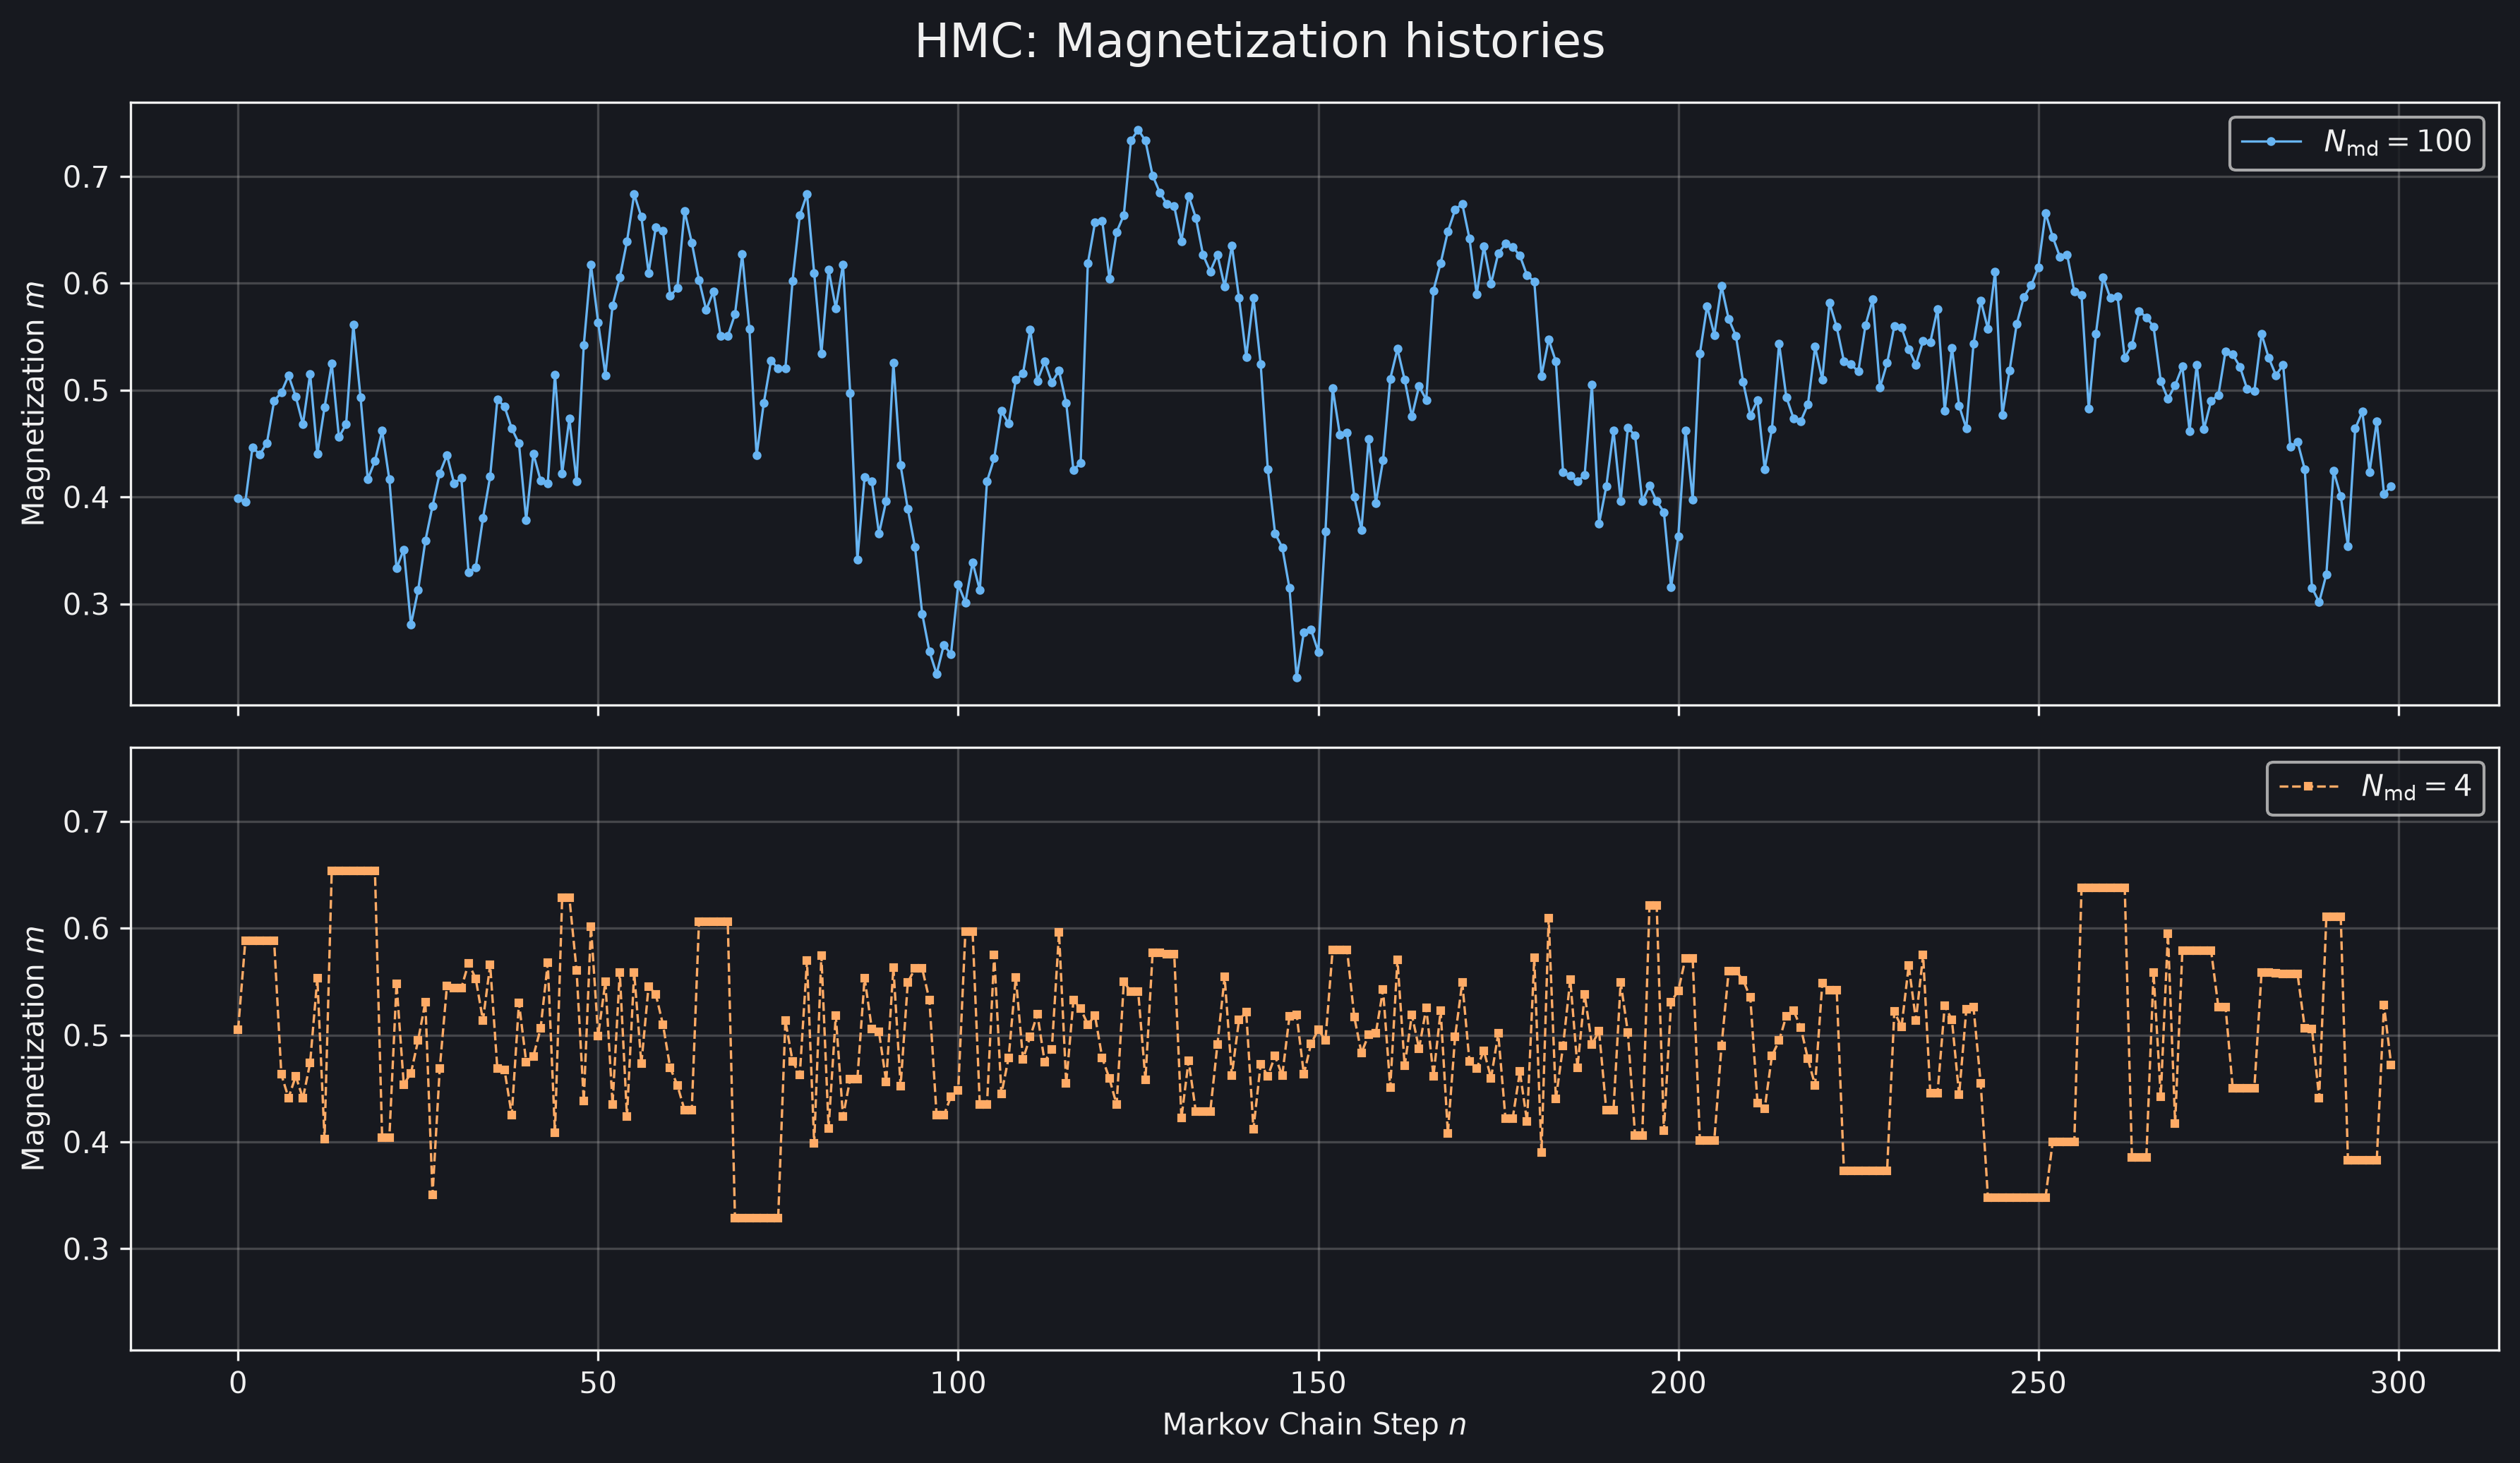

In [18]:
# ==============================================================
# Task 1: Plotting the Markov-chain histories
n_plot = 300

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True, dpi=300)

for i, N_md in enumerate(N_md_vals):
    m_samples = chains[N_md]["m"] # retrieve magnetization samples for this N_md

    axes[i].plot(
        np.arange(n_plot),
        m_samples[:n_plot],
        color=colors[i],
        linestyle=LINESTYLES[i],
        linewidth=0.8,
        marker=MARKERS[i],
        markersize=2,
        label=rf"$N_{{\text{{md}}}}={N_md}$"
    )

    axes[i].set_ylabel(r"Magnetization $m$")
    axes[i].legend()
    axes[i].grid(alpha=0.3)
axes[-1].set_xlabel(r"Markov Chain Step $n$")
fig.suptitle("HMC: Magnetization histories", fontsize=16)
plt.tight_layout()
plt.savefig("figs/hmc_magnetization_histories.pdf", dpi=300)
plt.savefig("figs/hmc_magnetization_histories.png", dpi=300)
plt.show()

# Task 2
Implement autocorrelation estimator $$\boxed{C(\tau) = \frac{\bar{\Gamma}^{(m)}(\tau)}{\bar{\Gamma}^{(m)}(0)}}$$
where $$\bar{\Gamma}^{(m)}(\tau) = \frac{1}{N-\tau} \sum_{k=0}^{N-\tau-1}\left( m_k-\bar{m} \right)\left( m_{k+\tau}-\bar{m} \right).$$

$\tau$ represents lag in Markov-chain steps.
- $C(0) = 1$ per definition
- $C(1)$ measures correlation between consecutive measurements
- $C(\tau) \rightarrow 0$ as separation increases (provided chain loses memory of a better life)

In [19]:
# ==============================================================
# Task 2: define autocorrelation function

def autocorrelation(m_samples, lag):
    """Calc normalized autocorr at given lag"""

    m_samples = np.asarray(m_samples)
    N = len(m_samples)

    # mean magnetization
    m_mean = np.mean(m_samples)

    # center measurements
    fluctuations = m_samples - m_mean

    # autocovariance at specified lag
    gamma_lag = np.sum(fluctuations[:N - lag] * fluctuations[lag:]) / (N - lag)

    # autocovariance at lag zero
    gamma_0 = np.sum(fluctuations**2) / N

    # normalized autocorrelation
    return gamma_lag / gamma_0

N_md=100:C(0) = 1.0000,C(1) = 0.8608,C(10) = 0.2098
N_md=4:C(0) = 1.0000,C(1) = 0.5955,C(10) = 0.2042


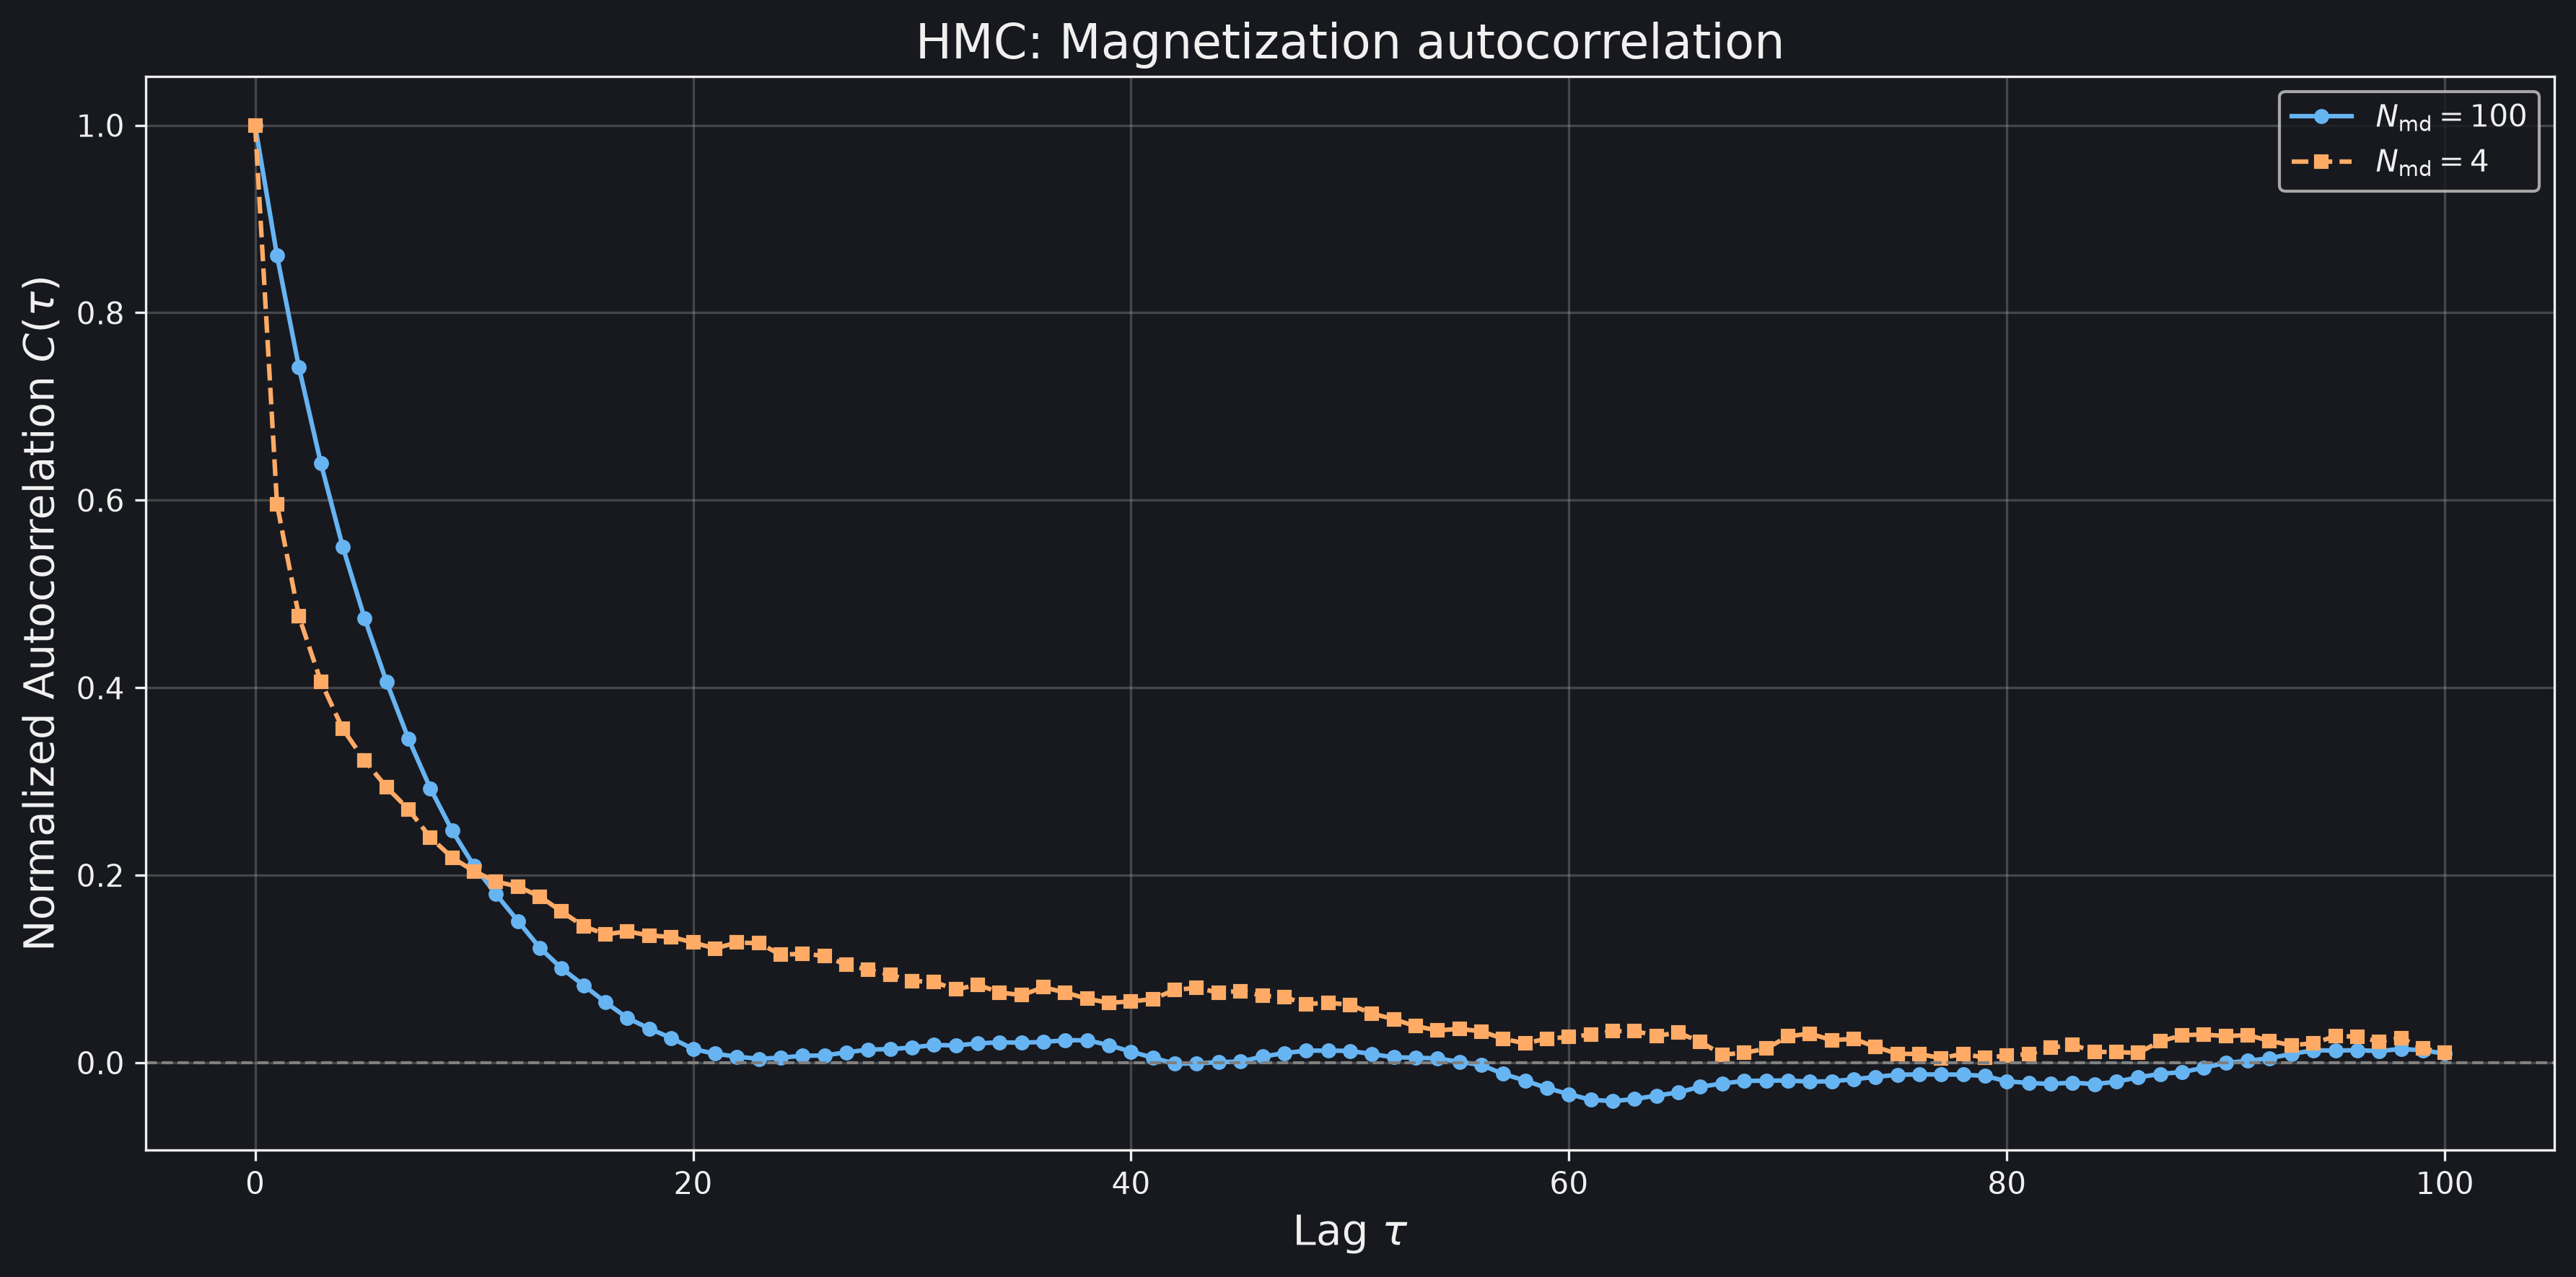

In [20]:
# ==============================================================
# Task 2: plot normalized autocorrelation function for each chain

max_lag = 100
lags = np.arange(max_lag + 1)

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

for i, N_md in enumerate(N_md_vals):

    # retrieve magnetisation samples
    m_samples = chains[N_md]["m"]

    # calc autocorr at each lag
    C_vals = np.array([autocorrelation(m_samples, lag) for lag in lags])

    ax.plot(
        lags,
        C_vals,
        color=colors[i],
        linestyle=LINESTYLES[i],
        linewidth=1.5,
        marker=MARKERS[i],
        markersize=4,
        label=rf"$N_{{\text{{md}}}}={N_md}$"
    )
    print(
        f"N_md={N_md}:"
        f"C(0) = {C_vals[0]:.4f},"
        f"C(1) = {C_vals[1]:.4f}," 
        f"C(10) = {C_vals[10]:.4f}"
    )
ax.axhline(0, color="gray", linestyle="--", linewidth=1.0)
ax.set_xlabel(r"Lag $\tau$", fontsize=14)
ax.set_ylabel(r"Normalized Autocorrelation $C(\tau)$", fontsize=14)
ax.set_title("HMC: Magnetization autocorrelation", fontsize=16)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
# plt.savefig("figs/hmc_magnetization_autocorrelation.pdf", dpi=300)
# plt.savefig("figs/hmc_magnetization_autocorrelation.png", dpi=300)
plt.show()